# Is this data real? A sanity check of two popular Kaggle datasets

**Why this matters.** Before analysing any dataset, an analyst should ask whether it can answer the question at
all. Two widely used Kaggle datasets, *Cyber Security Attacks* (40,000 rows) and *Air Quality and Health Impact*
(5,811 rows), are used in many portfolio projects to find "attack patterns" and "pollution-health links".

This notebook shows, with checks anyone can repeat, that **both are synthetic**: generated at random, with no
real-world relationships in them. Any "finding" drawn from them is noise.

*An earlier version of this repository drew conclusions from these datasets (e.g. "DDoS is the predominant
attack vector"). This notebook replaces that analysis and explains why those conclusions don't hold.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, GREY, INK = '#2a78d6', '#eb6834', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 12, 'font.size': 10})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches='tight'); plt.show()

cyber = pd.read_csv('data/cybersecurity_attacks.csv.gz')
air = pd.read_csv('data/air_quality_health_impact_data.csv.gz')
cyber.shape, air.shape

((40000, 25), (5811, 15))

## Part 1: Cyber Security Attacks

### Check 1. Do the place names make sense?
`Geo-location Data` holds values like `"Ghaziabad, Meghalaya"`. A real city belongs to one state. Count how many
different states each city appears with.

In [2]:
geo = cyber['Geo-location Data'].str.split(', ', expand=True)
geo.columns = ['city', 'state']
states_per_city = geo.groupby('city')['state'].nunique()
print(f"{geo['city'].nunique()} cities, {geo['state'].nunique()} states")
print(f"Every city appears in {states_per_city.min()} to {states_per_city.max()} different states")
print('Ghaziabad (a city in Uttar Pradesh) appears in:', ', '.join(sorted(geo.loc[geo.city == 'Ghaziabad', 'state'].unique())))

316 cities, 28 states
Every city appears in 24 to 28 different states
Ghaziabad (a city in Uttar Pradesh) appears in: Andhra Pradesh, Arunachal Pradesh, Assam, Bihar, Chhattisgarh, Goa, Gujarat, Haryana, Himachal Pradesh, Jharkhand, Karnataka, Kerala, Madhya Pradesh, Maharashtra, Manipur, Meghalaya, Mizoram, Nagaland, Odisha, Punjab, Rajasthan, Sikkim, Tamil Nadu, Telangana, Tripura, Uttar Pradesh, Uttarakhand, West Bengal


**Every city appears in at least 24 of the 28 states.** City and state were each picked at random and glued together, which is exactly how fake-data libraries (such as Python's `Faker`) produce addresses.

### Check 2. Do attackers ever repeat?
Real attack logs are dominated by repeat sources (botnets, scanners) and repeat targets (the same servers).

In [3]:
for col in ['Source IP Address', 'Destination IP Address']:
    print(f"{col}: {cyber[col].nunique():,} unique values in {len(cyber):,} rows")
print('\nSample payload:', cyber['Payload Data'].iloc[0][:90], '...')

Source IP Address: 40,000 unique values in 40,000 rows
Destination IP Address: 40,000 unique values in 40,000 rows

Sample payload: Qui natus odio asperiores nam. Optio nobis iusto accusamus ad perferendis esse at. Asperio ...


**Not one IP address repeats**, in 40,000 attacks. And the packet payloads are *lorem ipsum*, the Latin placeholder text used in design mock-ups.

### Check 3. Are the categories suspiciously even?
Real security data is lopsided: some attack types, protocols and severities are far more common than others.
A chi-square goodness-of-fit test asks whether the counts could have come from a perfectly even split
(a high p-value means *yes, they look perfectly even*).

In [4]:
category_cols = ['Attack Type', 'Severity Level', 'Protocol', 'Action Taken', 'Traffic Type',
                 'Network Segment', 'Packet Type', 'Log Source', 'Attack Signature']
rows = []
for col in category_cols:
    counts = cyber[col].value_counts()
    rows.append({'column': col, 'categories': len(counts),
                 'largest share %': round(counts.max() / counts.sum() * 100, 1),
                 'smallest share %': round(counts.min() / counts.sum() * 100, 1),
                 'p-value vs even split': round(stats.chisquare(counts.values).pvalue, 2)})
evenness = pd.DataFrame(rows)
evenness

,column,categories,largest share %,smallest share %,p-value vs even split
0,Attack Type,3,33.6,33.2,0.58
1,Severity Level,3,33.6,33.0,0.27
2,Protocol,3,33.6,33.2,0.59
3,Action Taken,3,33.8,33.0,0.10
4,Traffic Type,3,33.4,33.2,0.76
5,Network Segment,3,33.5,33.2,0.70
6,Packet Type,2,50.6,49.4,0.02
7,Log Source,2,50.3,49.7,0.25
8,Attack Signature,2,50.2,49.8,0.45


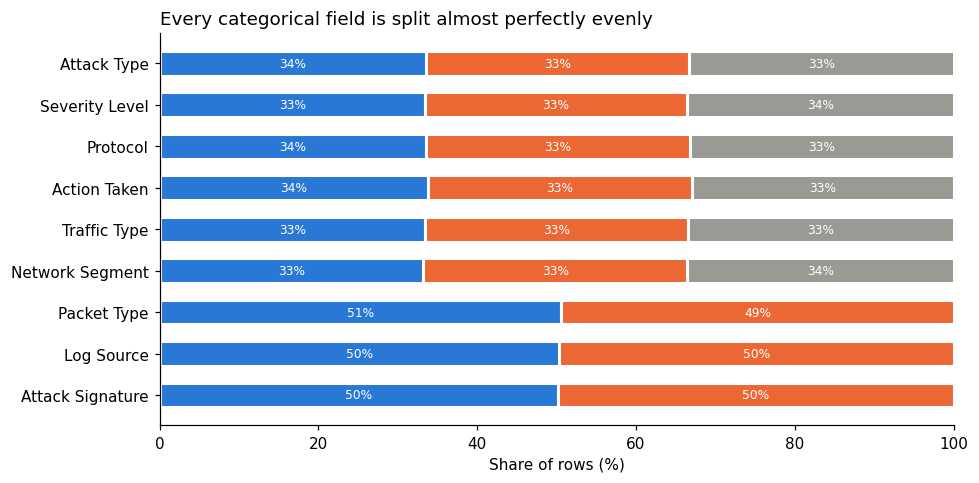

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, col in enumerate(category_cols):
    shares = cyber[col].value_counts(normalize=True).sort_index().values * 100
    left = 0
    for j, s in enumerate(shares):
        ax.barh(i, s, left=left, color=[BLUE, ORANGE, GREY][j % 3], edgecolor='white', linewidth=2, height=0.6)
        ax.text(left + s / 2, i, f'{s:.0f}%', ha='center', va='center', color='white', fontsize=8)
        left += s
ax.set_yticks(range(len(category_cols)), category_cols); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.set_xlabel('Share of rows (%)'); ax.grid(False)
ax.set_title('Every categorical field is split almost perfectly evenly')
save(fig, '01_even_categories.png')

In [6]:
# Real data: severity depends on the attack type. Here, do they move together at all?
table = pd.crosstab(cyber['Attack Type'], cyber['Severity Level'])
chi2, p, _, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"Attack type vs severity: Cramer's V = {cramers_v:.3f} (0 = unrelated, 1 = perfectly related), p = {p:.2f}")

hours = pd.to_datetime(cyber['Timestamp']).dt.hour.value_counts().sort_index()
print(f"Attacks per hour of day range from {hours.min():,} to {hours.max():,} (p vs flat = {stats.chisquare(hours.values).pvalue:.2f})")
table

Attack type vs severity: Cramer's V = 0.005 (0 = unrelated, 1 = perfectly related), p = 0.77
Attacks per hour of day range from 1,588 to 1,737 (p vs flat = 0.67)


Severity Level,High,Low,Medium
Attack Type,,,
DDoS,4523,4450,4455
Intrusion,4427,4374,4464
Malware,4432,4359,4516


**Attack type and severity are unrelated** (DDoS is no more or less severe than malware), and attacks are flat
across the day, with no business-hours or overnight pattern. Real traffic always has a daily rhythm.

**What this means for the old findings:** "DDoS is the predominant attack vector" (34% vs 33% vs 33%),
"medium severity is most common" (34% vs 33% vs 33%) and "Ghaziabad is a hotspot" (at most 16 attacks out of
40,000) are all random variation. The apparent "2023 decline" is because the data stops on 11 October 2023.

## Part 2: Air Quality and Health Impact

### Check 4. Is AQI related to the pollutants it is calculated from?
The Air Quality Index is *defined* from pollutant concentrations, PM2.5 above all. In real data the two are
almost perfectly related. Similarly, PM2.5 (fine particles) is part of PM10 (all particles under 10 µm), so the
two rise and fall together.

In [7]:
pairs = [('AQI', 'PM2_5'), ('AQI', 'PM10'), ('PM2_5', 'PM10'), ('AQI', 'RespiratoryCases'),
         ('PM2_5', 'RespiratoryCases'), ('AQI', 'HealthImpactScore')]
pd.DataFrame([{'pair': f'{a} vs {b}', 'correlation': round(air[a].corr(air[b]), 3)} for a, b in pairs])

,pair,correlation
0,AQI vs PM2_5,0.006
1,AQI vs PM10,0.023
2,PM2_5 vs PM10,-0.012
3,AQI vs RespiratoryCases,0.009
4,PM2_5 vs RespiratoryCases,0.025
5,AQI vs HealthImpactScore,0.615


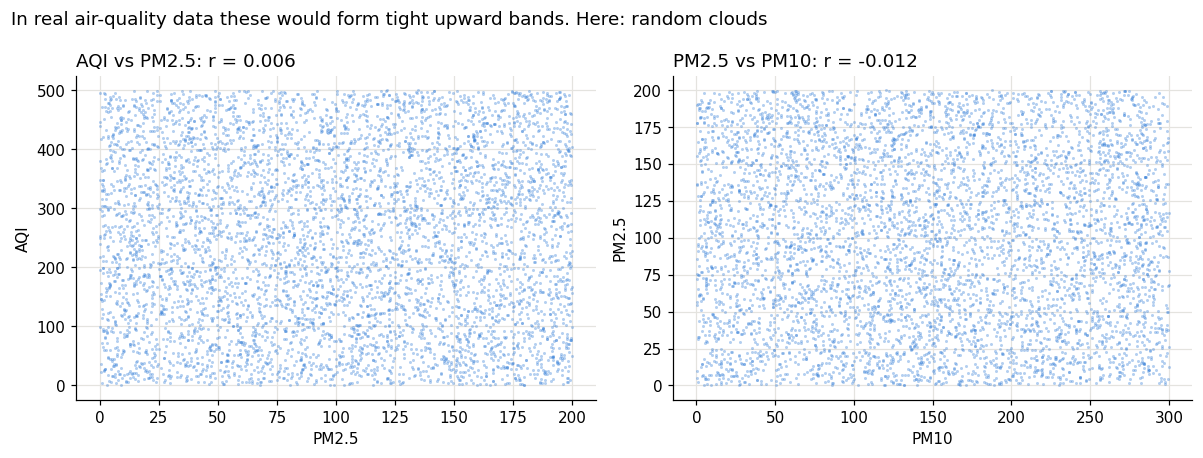

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (x, y) in zip(axes, [('PM2_5', 'AQI'), ('PM10', 'PM2_5')], strict=True):
    ax.scatter(air[x], air[y], s=4, alpha=0.35, color=BLUE, linewidths=0)
    ax.set_xlabel(x.replace('_', '.')); ax.set_ylabel(y.replace('_', '.'))
    ax.set_title(f'{y.replace("_", ".")} vs {x.replace("_", ".")}: r = {air[x].corr(air[y]):.3f}')
fig.suptitle('In real air-quality data these would form tight upward bands. Here: random clouds', x=0.01, ha='left', fontsize=12)
save(fig, '02_aqi_vs_pollutants.png')

**AQI has no relationship with PM2.5 or PM10.** That cannot happen with real AQI values; the columns were
generated independently.

### Check 5. Are the readings spread like real measurements?
Real pollution and weather readings cluster (most days are moderate, extreme days are rare). Uniformly random
values are spread flat across their range. The Kolmogorov-Smirnov test checks each column against a flat
(uniform) distribution; a high p-value means *indistinguishable from flat*.

In [9]:
rows = []
for col in ['AQI', 'PM2_5', 'O3', 'Temperature', 'Humidity', 'WindSpeed']:
    x = air[col]
    p = stats.kstest((x - x.min()) / (x.max() - x.min()), 'uniform').pvalue
    rows.append({'column': col, 'min': round(x.min(), 1), 'max': round(x.max(), 1), 'p-value vs flat': round(p, 2)})
pd.DataFrame(rows)

,column,min,max,p-value vs flat
0,AQI,0.0,499.9,0.82
1,PM2_5,0.0,200.0,0.72
2,O3,0.0,299.9,0.65
3,Temperature,-10.0,40.0,0.96
4,Humidity,10.0,100.0,0.83
5,WindSpeed,0.0,20.0,0.66


### Check 6. Do health outcomes respond to pollution at all?

Respiratory cases: mean 9.97, variance 9.79
A Poisson (purely random) count has variance equal to its mean.


Share of variation in respiratory cases explained by AQI, PM2.5, NO2 and weather: R² = 0.0013


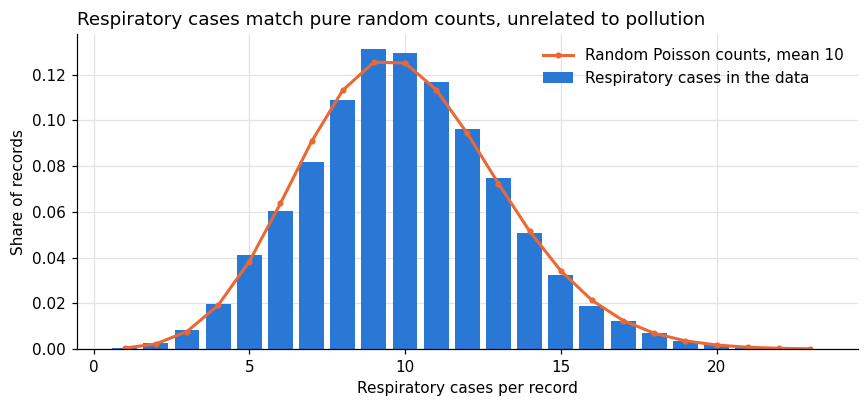

In [10]:
resp = air['RespiratoryCases']
print(f"Respiratory cases: mean {resp.mean():.2f}, variance {resp.var():.2f}")
print("A Poisson (purely random) count has variance equal to its mean.")

import statsmodels.api as sm

model = sm.OLS(resp, sm.add_constant(air[['AQI', 'PM2_5', 'NO2', 'Temperature', 'Humidity']])).fit()
print(f"Share of variation in respiratory cases explained by AQI, PM2.5, NO2 and weather: R² = {model.rsquared:.4f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
k = np.arange(resp.min(), resp.max() + 1)
ax.bar(k, resp.value_counts().reindex(k, fill_value=0) / len(resp), color=BLUE, width=0.8, label='Respiratory cases in the data')
ax.plot(k, stats.poisson.pmf(k, resp.mean()), color=ORANGE, lw=2, marker='o', ms=3, label=f'Random Poisson counts, mean {resp.mean():.0f}')
ax.set_xlabel('Respiratory cases per record'); ax.set_ylabel('Share of records'); ax.legend(frameon=False)
ax.set_title('Respiratory cases match pure random counts, unrelated to pollution')
save(fig, '03_respiratory_cases_random.png')

**Pollution explains 0.1% of the variation in respiratory cases**, and the counts match a random Poisson draw
almost exactly. The one column that does track AQI, `HealthImpactScore`, is a formula built from the other
columns and capped at 100 for most rows, so it cannot be used as independent evidence either.

**What this means for the old findings:** "a strong positive relationship between AQI and respiratory cases"
(actual correlation 0.009), "seasonal and daily patterns" (there is no date column) and "ARIMA forecasts"
(of row numbers, not time) do not hold.

## A reusable checklist: signs a dataset is synthetic

| Check | Real data usually | These datasets |
|---|---|---|
| Do linked fields agree (city ↔ state, AQI ↔ pollutants)? | Yes | **No**: each city in 24–28 of 28 states; AQI unrelated to PM2.5 |
| Do identifiers repeat (IPs, customers, devices)? | Heavily | **Never**: 40,000 unique source IPs |
| Are categories lopsided? | Usually | **Evenly split**, every column |
| Do related variables move together? | Yes | **No**: Cramér's V 0.005; r ≈ 0 |
| Are measurements clustered with long tails? | Yes | **Flat** across their range |
| Is there a time-of-day or seasonal rhythm? | Yes | **Flat**, or no dates at all |
| Is free text meaningful? | Yes | **Lorem ipsum** |

**Takeaway.** Five minutes of checks like these, before any modelling, would have shown that neither dataset
can answer the questions it is commonly used for. These datasets are still fine for practising tools (pivot
tables, charts, SQL syntax), as long as nobody presents the output as insight.

## Part 3: Turning the checks into a reusable tool

The checks above are packaged as **`datasanity`** (`src/datasanity`), a library and command-line tool that
runs eight kinds of check on any CSV or Excel file and gives a verdict:

| Verdict | Meaning |
|---|---|
| LIKELY SYNTHETIC | 2+ independent kinds of evidence of random generation |
| INVESTIGATE | 1 kind; real data can trip a single check (e.g. a column balanced by design) |
| NO SYNTHETIC SIGNALS | nothing found |

A detector is only useful if it stays quiet on real data, so it is validated on **both** synthetic datasets
and **three real ones** from this repository, which act as the false-positive control.

In [11]:
from pathlib import Path

from datasanity import check_file

files = {
    'Cyber Security Attacks (synthetic)': 'data/cybersecurity_attacks.csv.gz',
    'Air Quality and Health (synthetic)': 'data/air_quality_health_impact_data.csv.gz',
    'Netflix titles (real)': '../01-netflix-content-strategy/netflix_titles.csv',
    'Adani Ports prices (real)': '../02-adani-ports-stock-analysis/ADANIPORTS.csv',
    'NBA box scores (real)': '../03-nba-winning-performances/data/TeamStatistics.csv',
}
reports = {name: check_file(path) for name, path in files.items() if Path(path).exists()}
pd.DataFrame([{'dataset': name, 'rows': r.rows, 'checks applicable': sum(c.applicable for c in r.results),
               'checks triggered': len(r.triggered), 'verdict': r.verdict} for name, r in reports.items()]).set_index('dataset')

,rows,checks applicable,checks triggered,verdict
dataset,,,,
Cyber Security Attacks (synthetic),40000,8,8,LIKELY SYNTHETIC
Air Quality and Health (synthetic),5811,4,3,LIKELY SYNTHETIC
Netflix titles (real),8807,3,0,NO SYNTHETIC SIGNALS
Adani Ports prices (real),3322,5,0,NO SYNTHETIC SIGNALS
NBA box scores (real),147116,5,0,NO SYNTHETIC SIGNALS


In [12]:
# Which checks fired, dataset by dataset
pd.DataFrame({name: {c.check: ('TRIGGERED' if c.triggered else 'pass' if c.applicable else 'n/a') for c in r.results}
              for name, r in reports.items()})

,Cyber Security Attacks (synthetic),Air Quality and Health (synthetic),Netflix titles (real),Adani Ports prices (real),NBA box scores (real)
Evenly split categories,TRIGGERED,pass,pass,pass,pass
Flat numeric distributions,TRIGGERED,TRIGGERED,pass,pass,pass
No relationships between numeric columns,TRIGGERED,TRIGGERED,n/a,pass,pass
Place names that don't nest,TRIGGERED,n/a,n/a,n/a,n/a
Placeholder (lorem ipsum) text,TRIGGERED,n/a,pass,pass,pass
Network identifiers that never repeat,TRIGGERED,n/a,n/a,n/a,n/a
Leading digits break Benford's law,TRIGGERED,TRIGGERED,n/a,pass,n/a
No daily rhythm in timestamps,TRIGGERED,n/a,n/a,n/a,pass


Every synthetic dataset is flagged and every real one passes. The same tool runs from the command line,
for example as a gate in a data pipeline:

```bash
datasanity new_vendor_file.csv --fail-on-synthetic   # exit code 1 if LIKELY SYNTHETIC
```

**Limits.** It detects *naive* random generation (independent uniform draws, random pairing, placeholder text).
Data synthesised to preserve real distributions and correlations, e.g. by a generative model, is designed to pass
checks like these. Thresholds and their calibration are documented in `docs/methodology.md`.